# Synthetic Honeypot Logs Analysis

This notebook contains a detailed exploratory data analysis (EDA) and feature engineering of the synthetic honeypot logs generated over the past six months. The goal is to prepare the data for predictive modeling.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from datetime import datetime, timedelta
from geopy.distance import geodesic
import folium
from folium.plugins import HeatMap
import random
import os

## 1. Data Loading and Storage

Load the generated synthetic logs from Google Drive and store them in a SQLite database.

In [ ]:

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# Define paths
google_drive_path = "/content/drive/My Drive/synthetic_logs"

# Connect to SQLite database (or create it)
conn = sqlite3.connect('/content/drive/My Drive/synthetic_logs.db')
c = conn.cursor()

# Create table with all possible columns
c.execute('''
    CREATE TABLE IF NOT EXISTS honeypot_logs (
        timestamp TEXT,
        src TEXT,
        direction TEXT,
        protocol TEXT,
        ids_type TEXT,
        vendor_product TEXT,
        type TEXT,
        app TEXT,
        dest TEXT,
        dest_port INTEGER,
        signature TEXT,
        src_port INTEGER,
        sensor TEXT,
        transport TEXT,
        severity TEXT,
        dionaea_action TEXT
    )
''')
conn.commit()

# Load and insert data into the database
for date_str in os.listdir(google_drive_path):
    daily_data_path = os.path.join(google_drive_path, date_str, "logs.csv")
    if os.path.isfile(daily_data_path):
        daily_df = pd.read_csv(daily_data_path)
        # Ensure all columns are present
        if 'dionaea_action' not in daily_df.columns:
            daily_df['dionaea_action'] = None
        daily_df.to_sql('honeypot_logs', conn, if_exists='append', index=False)

# Verify data load
c.execute('SELECT COUNT(*) FROM honeypot_logs')
print(f"Number of records in the database: {c.fetchone()[0]}")

Mounted at /content/drive
Number of records in the database: 2711478


## 2. Initial Data Inspection

Let's start with a quick overview of the data to understand its structure.

In [ ]:
# Load data from SQLite into DataFrame for analysis
df = pd.read_sql('SELECT * FROM honeypot_logs', conn)

# Display the first few rows of the dataset
df.head()

,timestamp,src,direction,protocol,ids_type,vendor_product,type,app,dest,dest_port,signature,src_port,sensor,transport,severity,dionaea_action
0,2024-02-09T20:56:11.699888,192.168.1.97,inbound,tcp,network,Amun,amun.events,amun,10.0.2.16,3393,Normal Traffic|session_1|burst_1,36756,4debb22c-54a7-11ef-ab86-080027d27b60,tcp,high,None
1,2024-02-09T20:56:43.699888,192.168.1.43,inbound,tcp,network,Amun,amun.events,amun,10.0.2.16,3423,Brute Force|session_2|burst_9,7667,4debb22c-54a7-11ef-ab86-080027d27b60,tcp,medium,None
2,2024-02-09T20:57:24.699888,192.168.1.43,inbound,tcp,network,Amun,amun.events,amun,10.0.2.16,56,Brute Force|session_2|burst_9,29338,4debb22c-54a7-11ef-ab86-080027d27b60,tcp,high,None
3,2024-02-09T20:58:03.699888,192.168.1.43,inbound,tcp,network,Amun,amun.events,amun,10.0.2.16,114,Brute Force|session_2|burst_9,45231,4debb22c-54a7-11ef-ab86-080027d27b60,tcp,high,None
4,2024-02-09T20:58:03.699888,192.168.1.43,inbound,tcp,network,Amun,amun.events,amun,10.0.2.16,55,Brute Force|session_2|burst_9,6193,4debb22c-54a7-11ef-ab86-080027d27b60,tcp,high,None


In [ ]:
# Display summary statistics
# df.describe(include='all')

## 3. Exploratory Data Analysis (EDA)

### 3.1 Descriptive Statistics

In [ ]:
# Checking for missing values
df.isnull().sum()

,0
timestamp,0
src,0
direction,0
protocol,0
ids_type,0
vendor_product,0
type,0
app,0
dest,0
dest_port,0


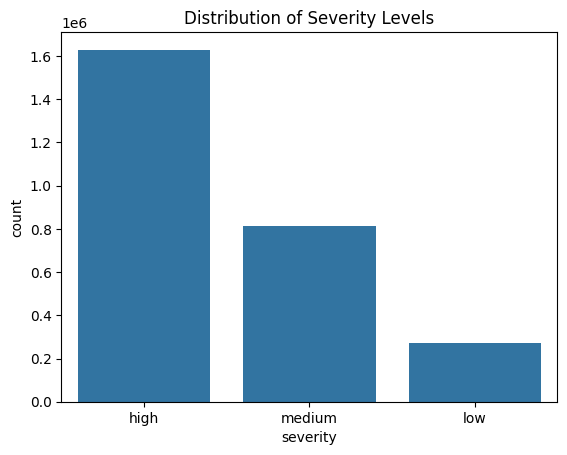

In [ ]:
# Distribution of severity levels
sns.countplot(data=df, x='severity')
plt.title('Distribution of Severity Levels')
plt.show()

### 3.2 Time-based Analysis

Let's analyze the data over time to identify any trends or patterns.

In [ ]:
# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

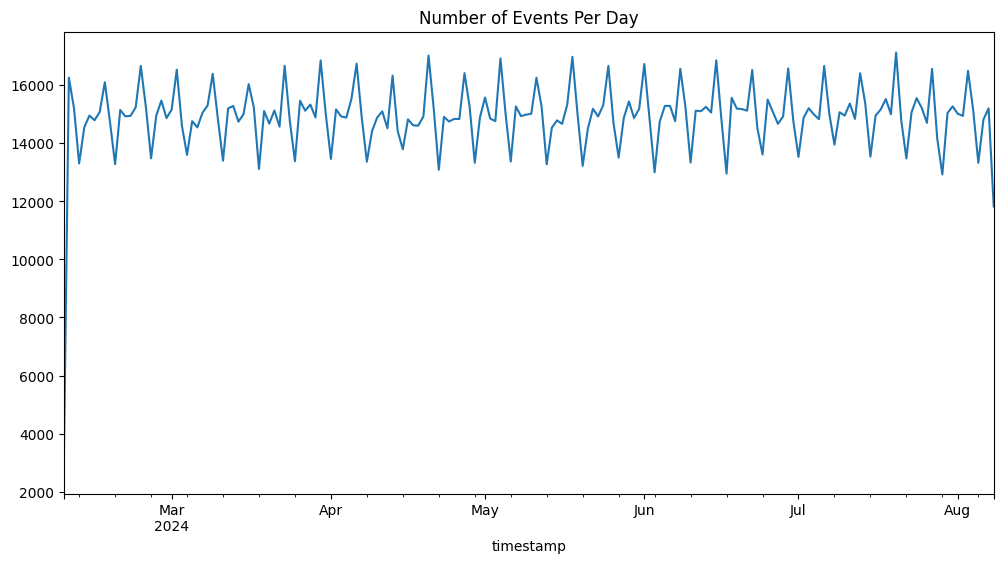

In [ ]:
# Plotting the number of events per day
df.set_index('timestamp').resample('D').size().plot(title='Number of Events Per Day', figsize=(12, 6))
plt.show()

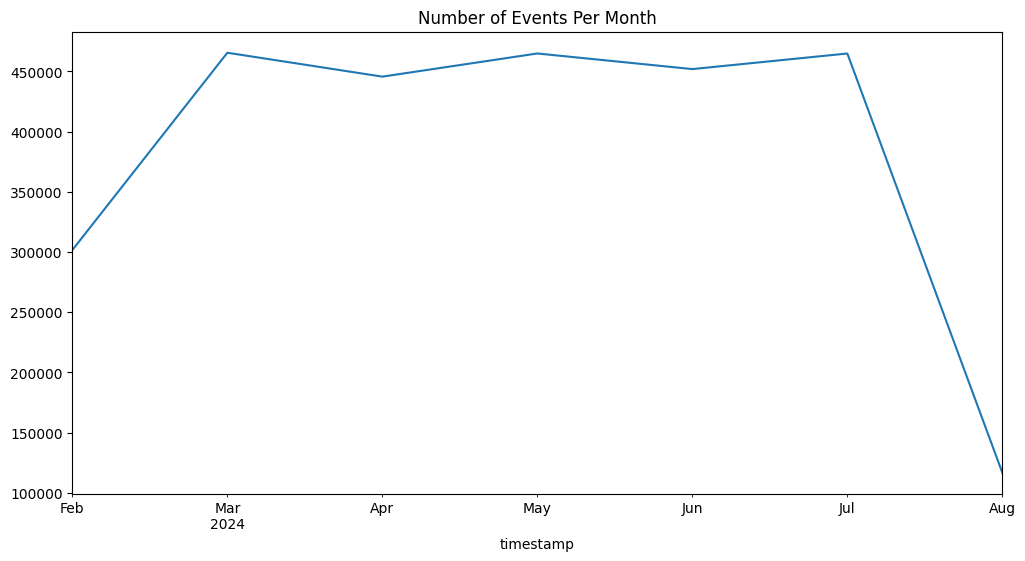

In [ ]:
# Plotting the number of events per month
df.set_index('timestamp').resample('M').size().plot(title='Number of Events Per Month', figsize=(12, 6))
plt.show()

### 3.3 Geographical Analysis

Analyze the data based on geographical locations of the source IPs.

In [ ]:
geoip_data = {
    "192.168.1.1": {"country": "US", "city": "New York", "latitude": 40.7128, "longitude": -74.0060},
    "192.168.1.2": {"country": "DE", "city": "Berlin", "latitude": 52.5200, "longitude": 13.4050},
    "192.168.1.3": {"country": "JP", "city": "Tokyo", "latitude": 35.6895, "longitude": 139.6917},
    "192.168.1.4": {"country": "IN", "city": "Mumbai", "latitude": 19.0760, "longitude": 72.8777},
    "192.168.2.1": {"country": "BR", "city": "Sao Paulo", "latitude": -23.5505, "longitude": -46.6333},
    "192.168.2.2": {"country": "ZA", "city": "Johannesburg", "latitude": -26.2041, "longitude": 28.0473},
    "192.168.3.1": {"country": "CN", "city": "Shanghai", "latitude": 31.2304, "longitude": 121.4737},
    "192.168.3.2": {"country": "AU", "city": "Sydney", "latitude": -33.8688, "longitude": 151.2093},
    "192.168.4.1": {"country": "FR", "city": "Paris", "latitude": 48.8566, "longitude": 2.3522},
    "192.168.4.2": {"country": "RU", "city": "Moscow", "latitude": 55.7558, "longitude": 37.6173}
}

# Generate more public IPs and corresponding GeoIP data
for i in range(5, 256):
    for j in range(1, 255):
        ip = f"192.168.{i}.{j}"
        geoip_data[ip] = {
            "country": random.choice(["US", "DE", "JP", "IN", "BR", "ZA", "CN", "AU", "FR", "RU"]),
            "latitude": np.random.uniform(-60, 60),    # Realistic latitude
            "longitude": np.random.uniform(-180, 180) # Realistic longitude
        }

# Function to calculate distance based on geo coordinates
def calculate_distance(src_ip, dest_coords=(51.509865, -0.118092)):  # Coordinates for London (default destination)
    if src_ip in geoip_data:
        src_coords = (geoip_data[src_ip]["latitude"], geoip_data[src_ip]["longitude"])
        distance = geodesic(src_coords, dest_coords).kilometers
        return distance if distance <= 8000 else np.nan  # Filter out distances greater than 8000 km
    return np.nan

# Apply distance calculation
df['distance'] = df['src'].apply(calculate_distance)

# Drop NaN values (filtered out distances greater than 8000 km)
df.dropna(subset=['distance'], inplace=True)



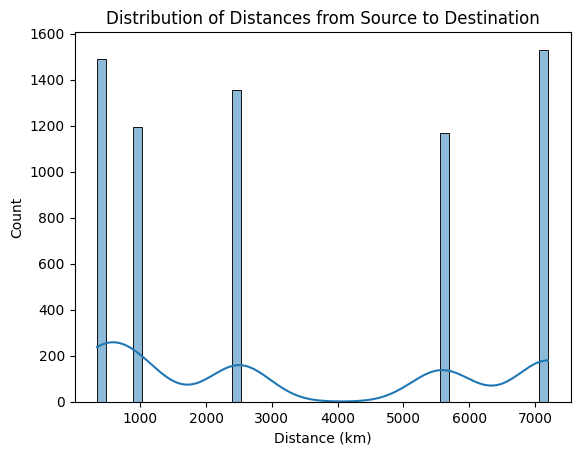

In [ ]:
# Plot distribution of distances
sns.histplot(df['distance'], bins=50, kde=True)
plt.title('Distribution of Distances from Source to Destination')
plt.xlabel('Distance (km)')
plt.ylabel('Count')
plt.show()


### 3.4 Attack Type Analysis

Analyze the data based on different attack types.

In [ ]:
# Extract attack type from the signature
top_attackers = df['src'].value_counts().head(10)


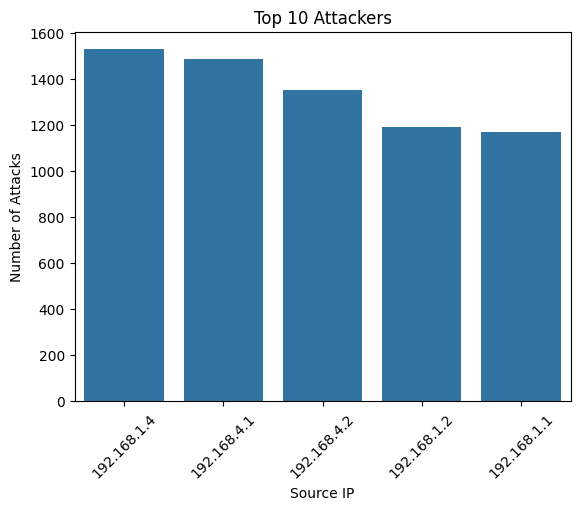

In [ ]:
# Plot top attackers
sns.barplot(x=top_attackers.index, y=top_attackers.values)
plt.title('Top 10 Attackers')
plt.xlabel('Source IP')
plt.ylabel('Number of Attacks')
plt.xticks(rotation=45)
plt.show()


### 3.5 Top Attackers Analysis

Identify and analyze the top attackers based on the frequency of attacks.

In [ ]:
# Frequency of attacks by hour
hourly_attacks = df.groupby(df['timestamp'].dt.hour).size()


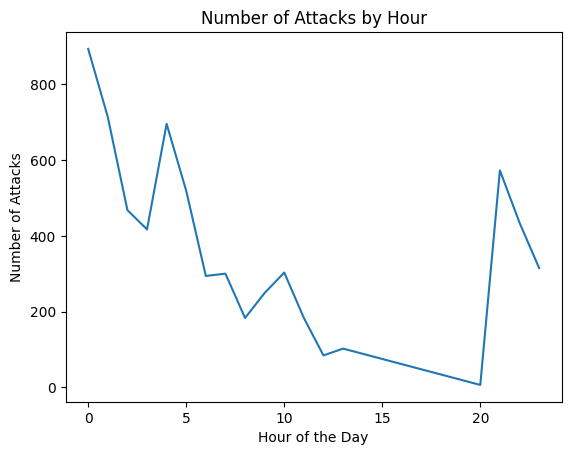

In [ ]:
# Plot hourly attack frequency
sns.lineplot(x=hourly_attacks.index, y=hourly_attacks.values)
plt.title('Number of Attacks by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Attacks')
plt.show()


### 3.6 Frequency Patterns

Analyze frequency patterns to identify any periodic trends in the attacks.

## 4. Feature Engineering

### 4.1 Temporal Features

Extract features related to time.

In [ ]:
# Extract hour, day, and month from timestamp
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['month'] = df['timestamp'].dt.month



NameError: name 'df' is not defined

### 4.3 Attack-related Features

Extract features related to attacks.

In [ ]:
# Extract session_id and burst_size from the signature
df['session_id'] = df['signature'].apply(lambda x: int(x.split('|')[1].split('_')[1]))
df['burst_size'] = df['signature'].apply(lambda x: int(x.split('|')[2].split('_')[1]))



### 4.4 Protocol-based Features

Features based on the protocol used in the traffic.

In [ ]:
# Encode protocol as a categorical feature
df['protocol'] = df['protocol'].astype('category').cat.codes

### 4.5 Frequency-based Features

Features based on the frequency of attacks from the same source IP.

In [ ]:
# Calculate frequency of attacks per source IP
df['attack_frequency'] = df.groupby('src')['src'].transform('count')

## 5. Conclusion

In this notebook, we performed a detailed exploratory data analysis and feature engineering on synthetic honeypot logs. The engineered features are now ready to be used for predictive modeling.

In [ ]:
# Save engineered data for further use
engineered_data_path = os.path.join(google_drive_path, "engineered_data.csv")
df.to_csv(engineered_data_path, index=False)

print("Feature engineering completed and saved to Google Drive.")

Feature engineering completed and saved to Google Drive.
